In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/train.csv")

In [3]:
df.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   object
 2   location  5080 non-null   object
 3   text      7613 non-null   object
 4   target    7613 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 297.5+ KB


In [5]:
df["target"].value_counts()

0    4342
1    3271
Name: target, dtype: int64

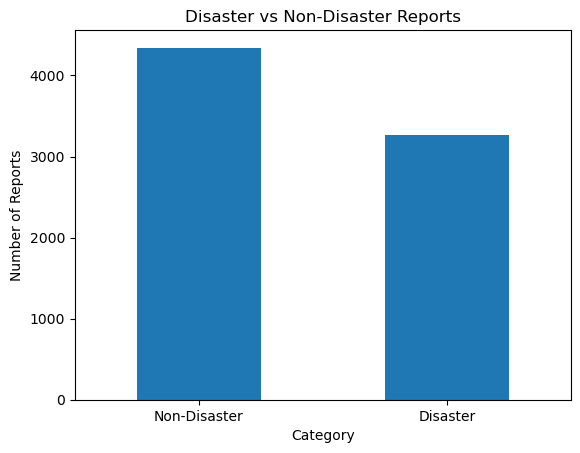

In [6]:
import matplotlib.pyplot as plt

df["target"].value_counts().plot(kind="bar")

plt.title("Disaster vs Non-Disaster Reports")
plt.xlabel("Category")
plt.ylabel("Number of Reports")
plt.xticks([0, 1], ["Non-Disaster", "Disaster"], rotation=0)

plt.show()

In [7]:
df["text"].duplicated().sum()

110

In [8]:
duplicates = df[df["text"].duplicated(keep=False)].sort_values("text")

duplicates[["text", "target"]].head(20)

,text,target
4290,#Allah describes piling up #wealth thinking it...,0
4299,#Allah describes piling up #wealth thinking it...,0
4312,#Allah describes piling up #wealth thinking it...,1
6363,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6373,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6377,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6378,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6392,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6366,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
2828,#KCA #VoteJKT48ID 12News: UPDATE: A family of ...,1


In [9]:
conflicting = (
    df.groupby("text")["target"]
    .nunique()
    .reset_index()
)

conflicting = conflicting[conflicting["target"] > 1]

print("Texts with conflicting labels:", len(conflicting))

Texts with conflicting labels: 18


In [10]:
conflicting_texts = df[df["text"].isin(conflicting["text"])]

conflicting_texts[["text", "target"]].sort_values("text")

,text,target
4290,#Allah describes piling up #wealth thinking it...,0
4299,#Allah describes piling up #wealth thinking it...,0
4312,#Allah describes piling up #wealth thinking it...,1
4244,#foodscare #offers2go #NestleIndia slips into ...,0
4221,#foodscare #offers2go #NestleIndia slips into ...,1
4239,#foodscare #offers2go #NestleIndia slips into ...,1
2832,.POTUS #StrategicPatience is a strategy for #G...,0
2831,.POTUS #StrategicPatience is a strategy for #G...,1
2830,.POTUS #StrategicPatience is a strategy for #G...,1
2833,.POTUS #StrategicPatience is a strategy for #G...,1


In [11]:
df_clean = df[~df["text"].isin(conflicting["text"])].copy()

print("Original rows:", len(df))
print("Rows after removing conflicts:", len(df_clean))

Original rows: 7613
Rows after removing conflicts: 7558


In [12]:
df_clean = df_clean.drop_duplicates(subset="text", keep="first").copy()

print("Rows after removing duplicates:", len(df_clean))

Rows after removing duplicates: 7485


In [13]:
df_clean[["text", "target"]].isnull().sum()

text      0
target    0
dtype: int64

In [14]:
df_clean["text"].head(10).tolist()

['Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all',
 'Forest fire near La Ronge Sask. Canada',
 "All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected",
 '13,000 people receive #wildfires evacuation orders in California ',
 'Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school ',
 '#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires',
 '#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas',
 "I'm on top of the hill and I can see a fire in the woods...",
 "There's an emergency evacuation happening now in the building across the street",
 "I'm afraid that the tornado is coming to our area..."]

In [15]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[@#]", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_clean["clean_text"] = df_clean["text"].apply(clean_text)

df_clean[["text", "clean_text"]].head(10)

,text,clean_text
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this earthquake ma...
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada
2,All residents asked to 'shelter in place' are ...,all residents asked to shelter in place are be...
3,"13,000 people receive #wildfires evacuation or...",people receive wildfires evacuation orders in ...
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...
5,#RockyFire Update => California Hwy. 20 closed...,rockyfire update california hwy closed in both...
6,#flood #disaster Heavy rain causes flash flood...,flood disaster heavy rain causes flash floodin...
7,I'm on top of the hill and I can see a fire in...,im on top of the hill and i can see a fire in ...
8,There's an emergency evacuation happening now ...,theres an emergency evacuation happening now i...
9,I'm afraid that the tornado is coming to our a...,im afraid that the tornado is coming to our area


In [16]:
df_clean.to_csv("../data/cleaned_disaster_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [17]:
print("Total records:", len(df_clean))
print("Total columns:", len(df_clean.columns))

Total records: 7485
Total columns: 6


In [18]:
from collections import Counter

words = " ".join(df_clean["clean_text"]).split()

word_counts = Counter(words)

word_counts.most_common(20)

[('the', 3213),
 ('a', 2153),
 ('in', 1940),
 ('to', 1913),
 ('of', 1779),
 ('i', 1392),
 ('and', 1389),
 ('is', 913),
 ('for', 869),
 ('on', 838),
 ('you', 777),
 ('my', 672),
 ('that', 552),
 ('it', 544),
 ('with', 541),
 ('at', 531),
 ('by', 514),
 ('this', 474),
 ('from', 405),
 ('be', 390)]

In [19]:
disaster_text = " ".join(
    df_clean[df_clean["target"] == 1]["clean_text"]
)

disaster_words = disaster_text.split()

disaster_counts = Counter(disaster_words)

disaster_counts.most_common(20)

[('the', 1328),
 ('in', 1135),
 ('a', 912),
 ('of', 893),
 ('to', 743),
 ('and', 488),
 ('on', 405),
 ('for', 381),
 ('is', 336),
 ('i', 319),
 ('at', 301),
 ('by', 272),
 ('from', 233),
 ('that', 181),
 ('this', 179),
 ('fire', 175),
 ('after', 171),
 ('it', 167),
 ('was', 166),
 ('with', 166)]

In [20]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

disaster_words_filtered = [
    word for word in disaster_words
    if word not in ENGLISH_STOP_WORDS
]

disaster_counts_filtered = Counter(disaster_words_filtered)

disaster_counts_filtered.most_common(20)

[('news', 139),
 ('disaster', 112),
 ('california', 110),
 ('amp', 106),
 ('police', 105),
 ('suicide', 104),
 ('people', 101),
 ('killed', 93),
 ('like', 89),
 ('hiroshima', 88),
 ('pm', 87),
 ('just', 85),
 ('storm', 85),
 ('crash', 84),
 ('fires', 83),
 ('families', 79),
 ('emergency', 76),
 ('train', 71),
 ('nuclear', 71),
 ('bomb', 70)]

In [21]:
non_disaster_text = " ".join(
    df_clean[df_clean["target"] == 0]["clean_text"]
)

non_disaster_words = non_disaster_text.split()

non_disaster_words_filtered = [
    word for word in non_disaster_words
    if word not in ENGLISH_STOP_WORDS
]

non_disaster_counts = Counter(non_disaster_words_filtered)

non_disaster_counts.most_common(20)

[('like', 251),
 ('im', 243),
 ('just', 234),
 ('amp', 192),
 ('new', 170),
 ('dont', 149),
 ('body', 113),
 ('video', 95),
 ('love', 90),
 ('people', 88),
 ('know', 85),
 ('time', 83),
 ('got', 83),
 ('day', 81),
 ('emergency', 80),
 ('youtube', 76),
 ('going', 75),
 ('good', 67),
 ('want', 64),
 ('think', 64)]

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X = tfidf.fit_transform(df_clean["clean_text"])
y = df_clean["target"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (7485, 5000)
Target shape: (7485,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5988
Testing samples: 1497


In [24]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [25]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

Predictions completed!
Number of predictions: 1497


In [26]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Disaster", "Disaster"]
))

Accuracy: 0.7855711422845691

Classification Report:
              precision    recall  f1-score   support

Non-Disaster       0.76      0.91      0.83       859
    Disaster       0.84      0.62      0.71       638

    accuracy                           0.79      1497
   macro avg       0.80      0.76      0.77      1497
weighted avg       0.79      0.79      0.78      1497



Confusion Matrix:
[[783  76]
 [245 393]]


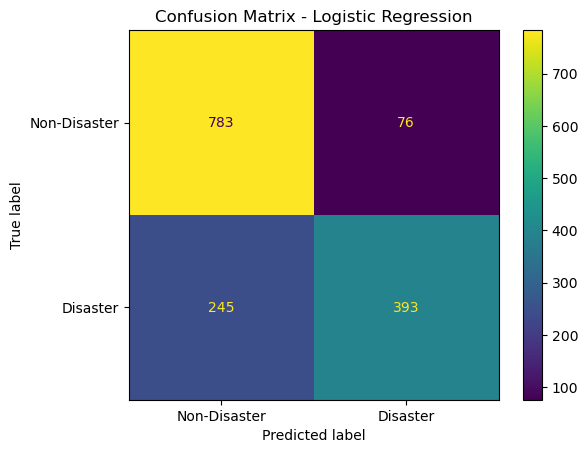

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Disaster", "Disaster"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [28]:
tfidf_improved = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_features=10000,
    sublinear_tf=True
)

X_improved = tfidf_improved.fit_transform(df_clean["clean_text"])

print("Improved feature matrix shape:", X_improved.shape)

Improved feature matrix shape: (7485, 10000)


In [29]:
X_train_imp, X_test_imp, y_train_imp, y_test_imp = train_test_split(
    X_improved,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Improved training samples:", X_train_imp.shape[0])
print("Improved testing samples:", X_test_imp.shape[0])

Improved training samples: 5988
Improved testing samples: 1497


In [30]:
model_improved = LogisticRegression(max_iter=1000)

model_improved.fit(X_train_imp, y_train_imp)

print("Improved model training completed successfully!")

Improved model training completed successfully!


In [31]:
y_pred_imp = model_improved.predict(X_test_imp)

print("Improved predictions completed!")
print("Number of predictions:", len(y_pred_imp))

Improved predictions completed!
Number of predictions: 1497


In [32]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_imp = accuracy_score(y_test_imp, y_pred_imp)

print("Improved Model Accuracy:", accuracy_imp)

print("\nImproved Classification Report:")
print(classification_report(
    y_test_imp,
    y_pred_imp,
    target_names=["Non-Disaster", "Disaster"]
))

Improved Model Accuracy: 0.7808951235804943

Improved Classification Report:
              precision    recall  f1-score   support

Non-Disaster       0.76      0.91      0.83       859
    Disaster       0.83      0.61      0.70       638

    accuracy                           0.78      1497
   macro avg       0.80      0.76      0.76      1497
weighted avg       0.79      0.78      0.77      1497



In [33]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train, y_train)

print("Linear SVM training completed successfully!")

Linear SVM training completed successfully!


In [34]:
y_pred_svm = svm_model.predict(X_test)

print("SVM predictions completed!")
print("Number of predictions:", len(y_pred_svm))

SVM predictions completed!
Number of predictions: 1497


In [35]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("Linear SVM Accuracy:", accuracy_svm)

print("\nLinear SVM Classification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["Non-Disaster", "Disaster"]
))

Linear SVM Accuracy: 0.7615230460921844

Linear SVM Classification Report:
              precision    recall  f1-score   support

Non-Disaster       0.76      0.85      0.80       859
    Disaster       0.76      0.64      0.70       638

    accuracy                           0.76      1497
   macro avg       0.76      0.75      0.75      1497
weighted avg       0.76      0.76      0.76      1497



In [36]:
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_model.fit(X_train, y_train)

print("Balanced Logistic Regression training completed successfully!")

Balanced Logistic Regression training completed successfully!


In [37]:
y_pred_balanced = balanced_model.predict(X_test)

print("Balanced model predictions completed!")
print("Number of predictions:", len(y_pred_balanced))

Balanced model predictions completed!
Number of predictions: 1497


In [38]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_balanced = accuracy_score(y_test, y_pred_balanced)

print("Balanced Logistic Regression Accuracy:", accuracy_balanced)

print("\nBalanced Classification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Non-Disaster", "Disaster"]
))

Balanced Logistic Regression Accuracy: 0.7889111556446226

Balanced Classification Report:
              precision    recall  f1-score   support

Non-Disaster       0.79      0.86      0.82       859
    Disaster       0.79      0.69      0.74       638

    accuracy                           0.79      1497
   macro avg       0.79      0.78      0.78      1497
weighted avg       0.79      0.79      0.79      1497



Balanced Model Confusion Matrix:
[[738 121]
 [195 443]]


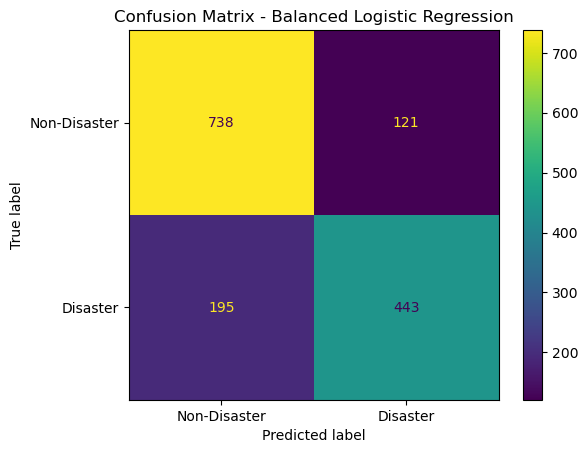

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

print("Balanced Model Confusion Matrix:")
print(cm_balanced)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["Non-Disaster", "Disaster"]
)

disp.plot()
plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.show()

In [40]:
import joblib

# Save the best trained model
joblib.dump(balanced_model, "disaster_model.pkl")

# Save the original TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!


In [41]:
# Test the trained AI with a new report

new_report = [
    "Heavy rainfall has caused severe flooding in Mumbai"
]

# Convert the new text into TF-IDF features
new_report_tfidf = tfidf.transform(new_report)

# Make prediction
prediction = balanced_model.predict(new_report_tfidf)

if prediction[0] == 1:
    print("Prediction: DISASTER")
else:
    print("Prediction: NON-DISASTER")

Prediction: DISASTER


In [42]:
# Get prediction probabilities

probabilities = balanced_model.predict_proba(new_report_tfidf)

disaster_probability = probabilities[0][1]
non_disaster_probability = probabilities[0][0]

print("Prediction:", "DISASTER" if prediction[0] == 1 else "NON-DISASTER")

print("Disaster Probability:", round(disaster_probability * 100, 2), "%")
print("Non-Disaster Probability:", round(non_disaster_probability * 100, 2), "%")

Prediction: DISASTER
Disaster Probability: 90.55 %
Non-Disaster Probability: 9.45 %


In [43]:
def predict_disaster(report):

    # Convert text into TF-IDF
    report_tfidf = tfidf.transform([report])

    # Get prediction
    result = balanced_model.predict(report_tfidf)[0]

    # Get probabilities
    probabilities = balanced_model.predict_proba(report_tfidf)[0]

    non_disaster_prob = probabilities[0] * 100
    disaster_prob = probabilities[1] * 100

    # Display result
    if result == 1:
        print("PREDICTION: DISASTER")
    else:
        print("PREDICTION: NON-DISASTER")

    print(f"Disaster Probability: {disaster_prob:.2f}%")
    print(f"Non-Disaster Probability: {non_disaster_prob:.2f}%")

In [44]:
predict_disaster(
    "A powerful earthquake has damaged several buildings and roads."
)

PREDICTION: DISASTER
Disaster Probability: 80.04%
Non-Disaster Probability: 19.96%
